# Multigrain Tutorial

This tutorial generates a tetrahedral four-grain geometry with an explicit grain-boundary phase, explores the mesh interactively with PyVista, and converts it into a region-aware Ubermag system for TOMMOS.

In [48]:
from contextlib import chdir
from pathlib import Path

import matplotlib.pyplot as plt
import micromagneticmodel as mm
import numpy as np
import pyvista as pv

import tommos_adapter as ta

# Trame provides the interactive PyVista view inside Jupyter.
pv.set_jupyter_backend("trame")

## Generate a multigrain mesh using TOMMOS and Neper

TOMMOS delegates the polycrystal construction to Neper and then creates a tetrahedral volume mesh. The command below generates a $40\,\mathrm{nm}$ cube containing four grains. `--h` controls the target grain-mesh spacing, while `--gb-thickness` and `--gb-h` control the explicit grain-boundary phase. `--id 7` selects a fixed Neper seed for the microstructure.

Two files are written: `multigrain.npz` contains the TOMMOS solver mesh and `multigrain.vtu` contains the equivalent mesh for visualization and further processing with PyVista.

In [49]:
!tommos mesh \
    --geom poly_gb \
    --extent 40,40,40 \
    --h 3 \
    --n 4 \
    --id 7 \
    --gb-thickness 2 \
    --gb-h 1.5 \
    --out-name multigrain


========================    N   e   p   e   r    =======================
Info   : A software package for polycrystal generation and meshing.
Info   : Version 5.0.0
Info   : Built with: gsl|muparser|opengjk|openmp|nlopt|libscotch (full)
Info   : Running on 10 threads.
Info   : <https://neper.info>
Info   : Copyright (C) 2003-2026, and GNU GPL'd, by Romain Quey, CNRS.
Info   : No initialization file found (`/Users/michael/.neperrc').
Info   : ---------------------------------------------------------------
Info   : MODULE  -T loaded with arguments:
Info   : [ini file] (none)
Info   : [com line] -n 4 -id 7 -morpho gg -morphooptistop val=0.1 -domain
         cube(40.0,40.0,40.0):translate(0,0,0) -format tess,obj -reg 1
Info   : ---------------------------------------------------------------
Info   : Reading input data...
Info   : Creating domain...
Info   : Creating tessellation...
Info   :   - Setting seeds... 255075100%
Info   :   - Running tessellation...
Info   :     > Initial solution

## Inspect the generated mesh using PyVista

### Import the VTU file and check its regions

The VTU file stores the tetrahedral mesh and one material ID for each cell. The following summary reports the number of points and cells, the spatial extents, and the number of tetrahedra belonging to every material. This is a useful first consistency check before assigning physical parameters.

In [50]:
mesh_nm = pv.read("multigrain.vtu")
# TOMMOS stores one material identifier per tetrahedron.
material_ids = np.asarray(mesh_nm.cell_data["mat_id"])

print(mesh_nm)
print("Material IDs:", np.unique(material_ids))

ids, counts = np.unique(material_ids, return_counts=True)
for material_id, count in zip(ids, counts, strict=True):
    print(f"Material {material_id}: {count} tetrahedra")

UnstructuredGrid (0x35574fd60)
  N Cells:    416518
  N Points:   82932
  X Bounds:   -2.000e+01, 2.000e+01
  Y Bounds:   -2.000e+01, 2.000e+01
  Z Bounds:   -2.000e+01, 2.000e+01
  N Arrays:   1
Material IDs: [1 2 3 4 5]
Material 1: 16620 tetrahedra
Material 2: 34335 tetrahedra
Material 3: 66248 tetrahedra
Material 4: 16837 tetrahedra
Material 5: 282478 tetrahedra


### Explore two-dimensional slices of the tetrahedral mesh

A full tetrahedral mesh can be difficult to inspect from the outside. The following plot therefore shows an $xy$ section through the mesh. Move the slider to select the section's $z$ coordinate; colors denote the material IDs and the black box marks the full mesh extent.

In [51]:
material_ids = np.asarray(mesh_nm.cell_data["mat_id"])
z_min, z_max = mesh_nm.bounds[4], mesh_nm.bounds[5]
z_initial = 0.0

# Create the initial xy section through the center of the mesh.
section = mesh_nm.slice(
    normal=(0, 0, 1),
    origin=(0, 0, z_initial),
)

slice_plotter = pv.Plotter()


# Keep the bounding box visible while the section moves.
slice_plotter.add_mesh(
    mesh_nm.outline(),
    color="black",
    line_width=2,
)


slice_plotter.add_mesh(
    section,
    scalars="mat_id",
    categories=True,
    cmap="tab10",
    clim=(material_ids.min(), material_ids.max()),
    show_edges=True,
    scalar_bar_args={"title": "Region"},
)


def update_slice(
    z,
    source_mesh=mesh_nm,
    target_section=section,
    target_plotter=slice_plotter,
):
    """Move the section along the z-axis."""
    new_section = source_mesh.slice(
        normal=(0, 0, 1),
        origin=(0, 0, float(z)),
    )
    # Update the existing actor instead of creating a new plot for every position.
    target_section.copy_from(new_section, deep=True)
    target_plotter.render()


slice_plotter.add_slider_widget(
    update_slice,
    rng=(z_min, z_max),
    value=z_initial,
    title="z [nm]",
    fmt="%.1f",
    interaction_event="end",
)

slice_plotter.show(jupyter_backend="trame")

### Inspect the grains and grain boundary in three dimensions

The next view separates the magnetic grains from the grain-boundary phase. The grains are colored by material ID, while the grain boundary is rendered transparently so that the internal microstructure remains visible.

In [52]:
# The poly_gb mesher assigns the final material ID to the grain boundary.
gb_id = material_ids.max()

grains = mesh_nm.extract_cells(material_ids != gb_id)
grain_boundary = mesh_nm.extract_cells(material_ids == gb_id)

overview_plotter = pv.Plotter()
overview_plotter.add_mesh(
    grains,
    scalars="mat_id",
    categories=True,
    cmap="tab10",
    show_edges=False,
)
overview_plotter.add_mesh(
    grain_boundary,
    color="lightgray",
    opacity=0.12,
)
overview_plotter.add_axes()
overview_plotter.show(jupyter_backend="trame")

## Prepare the mesh for Ubermag

The generated coordinates are expressed in nanometres, whereas Ubermag models use SI units. The adapter also expects the cell-wise material identifiers under `region_id`, optional human-readable region metadata in `field_data`, and a unit magnetization vector `m` at every mesh point.

In [53]:
mesh_si = mesh_nm.copy(deep=True)
# Convert the mesh coordinates from nanometres to metres.
mesh_si.points *= ta.scripts.DEFAULT_MESH_UNIT

# Rename TOMMOS material IDs to the adapter's region-data convention.
region_id = mesh_si.get_array("mat_id").astype(int)
mesh_si.cell_data["region_id"] = region_id
mesh_si.cell_data.remove("mat_id")

ids = np.unique(region_id)
gb_id = ids.max()
names = [f"grain_{i}" if i != gb_id else "grain_boundary" for i in ids]

# Region names allow energy parameters to be assigned with dictionaries.
mesh_si.field_data["region_ids"] = ids
mesh_si.field_data["region_names"] = names
# Start from a uniform, normalized magnetization along +z.
mesh_si.point_data["m"] = np.tile((0, 0, 1), (mesh_si.n_points, 1))

## Define the Ubermag system

The material parameters below are illustrative. The four grains are magnetic and share the same material parameters and easy-axis direction. The grain-boundary phase is non-magnetic. Region dictionaries connect the named PyVista regions to the corresponding Ubermag energy parameters.

In [54]:
grain_names = [name for name in names if name != "grain_boundary"]

# Assign one material-parameter value to every named region.
Ms_by_region = {name: 1e6 for name in grain_names}  # A/m
A_by_region = {name: 1e-11 for name in grain_names}  # J/m
K_by_region = {name: 4e5 for name in grain_names}  # J/m^3
u_by_region = {name: (0, 0, 1) for name in grain_names}

Ms_by_region["grain_boundary"] = 0.0
A_by_region["grain_boundary"] = 0.0
K_by_region["grain_boundary"] = 0.0
# A unit easy axis is still required by the data model, although K is zero here.
u_by_region["grain_boundary"] = (0, 0, 1)

# Ms is stored per tetrahedron; the energy parameters remain region dictionaries.
name_by_id = dict(zip(ids, names, strict=True))
mesh_si.cell_data["Ms"] = np.array(
    [Ms_by_region[name_by_id[material_id]] for material_id in region_id]
)

system = mm.System(name="multigrain")
system.m = mesh_si
system.energy = (
    mm.Exchange(A=A_by_region)
    + mm.UniaxialAnisotropy(K=K_by_region, u=u_by_region)
    + mm.Demag()
)
system

System(name='multigrain')

## Prepare a hysteresis calculation

The following field sweep starts at $+2\,\mathrm{T}$ along the easy axis and ends at $-2\,\mathrm{T}$. Five field points and relaxed minimizer settings are sufficient for an initial technical smoke test; they are not intended to produce a well-resolved physical hysteresis curve.

In [55]:
B_start = 2.0  # T
B_stop = -2.0  # T

H_start = (0, 0, B_start / mm.consts.mu0)
H_stop = (0, 0, B_stop / mm.consts.mu0)
n = 30

hd = ta.HysteresisDriver(
    max_iter=200,
    tol_fun=1e-6,
    eps_a="auto",
)

## Write the TOMMOS input files

Normally, `hd.drive(...)` performs all subsequent steps: it validates the system, creates a drive directory, writes the input files, starts TOMMOS, and reads the result. For the temporary direct TOMMOS call used here, we stop after writing the inputs.

The adapter's internal writing method creates `multigrain.npz`, `multigrain.krn`, and `multigrain.p2` in a separate `multigrain-direct` directory, leaving the original mesh files untouched. This use of private methods is deliberately temporary and can be replaced by the regular driver call once the Airbox integration is available.

In [56]:
run_directory = Path("multigrain-direct")
run_directory.mkdir(exist_ok=True)

driver_kwargs = {"Hmin": H_start, "Hmax": H_stop, "n": n}
hd.drive_kwargs_setup(driver_kwargs)
hd._check_system(system)

with chdir(run_directory):
    hd._write_input_files(system, **driver_kwargs)

input_files = [run_directory / f"{system.name}{suffix}" for suffix in (".npz", ".krn", ".p2")]
for input_file in input_files:
    print(f"{input_file}: {input_file.stat().st_size:,} bytes")

multigrain-direct/multigrain.npz: 18,651,586 bytes
multigrain-direct/multigrain.krn: 232 bytes
multigrain-direct/multigrain.p2: 231 bytes


## Run TOMMOS directly with an Airbox

The regular adapter call is shown as a comment for the future implementation. For now, the command-line call starts TOMMOS in the input directory and explicitly requests the Airbox with `--add-shell`. `OPENBLAS_NUM_THREADS=1` avoids the intermittent JAX/OpenBLAS stack overflow observed on macOS.

The cell is marked with `NBVAL_SKIP` because this full simulation must not run as part of the automated notebook tests. Execute it manually when the calculation should start. The current mesh contains 416,518 tetrahedra before the Airbox is added, so this is not a lightweight smoke test; use a coarser mesh first if short turnaround is important.

In [57]:
# NBVAL_SKIP
# Future standard adapter call:
# hd.drive(system, Hmin=H_start, Hmax=H_stop, n=n)

!cd multigrain-direct && \
    OPENBLAS_NUM_THREADS=1 tommos loop multigrain \
    --loop \
    --add-shell \
    --cpu-spmv-backend scipy \
    --no-cpp-mkl

[config] JAX initialized with 1 total devices.
Layer |         sx |         sy |         sz
------+------------+------------+-----------
    1 |   1.083333 |   1.083333 |   1.083333
    2 |   1.416667 |   1.416667 |   1.416667
    3 |   2.187500 |   2.187500 |   2.187500
    4 |   3.708333 |   3.708333 |   3.708333
    5 |   6.494792 |   6.494792 |   6.494792
    6 |  11.390625 |  11.390625 |  11.390625
[validate] welded duplicate nodes: 27669

=== AIRBOX MESH ANALYSIS ===
Core Elements  : 416,518
Shell Elements : 164,457 (Total: 580,975)
Nodes          : 98,362
Airbox Extents : [455.6, 455.6, 455.6]
Airbox Volume  : 9.46e+07
Shell Quality  : Mean = 0.4826, Min = 0.0096


=== HARDWARE & MEMORY ANALYSIS ===
Hardware       : CPU (1 device)
Mesh Nodes     : 98,362
Mesh Elements  : 580,975
Available RAM  : 2,921.7 MB
Estimated Peak : 341.3 MB

[config] Loading base settings from multigrain.p2
Assembling global sparse operators on CPU...
[ok] Finished assembly and GPU transfer.
Setting up A

## Read the TOMMOS results with PyVista

TOMMOS writes one VTU snapshot for every saved field configuration. PyVista reads the final snapshot as an `UnstructuredGrid`, including the magnetic grains, the grain-boundary phase, and the newly generated Airbox. The largest material ID identifies the Airbox.

For visualization, the coordinates remain in TOMMOS mesh units (nanometres in this example). A later adapter implementation must convert them back to metres and reconstruct the Ubermag region metadata before assigning the result to `system.m`.

In [58]:
# NBVAL_SKIP
# Future standard adapter results:
# result_si = system.m
# hysteresis_table = system.table

output_directory = run_directory / f"hyst_{system.name}"
snapshots = sorted(output_directory.glob("state_cfg*.vtu"))
if not snapshots:
    raise RuntimeError("TOMMOS did not produce any VTU snapshots.")

result_nm = pv.read(snapshots[-1])
if "m" not in result_nm.point_data:
    raise RuntimeError("The TOMMOS snapshot does not contain point data 'm'.")

result_material_ids = np.asarray(result_nm.cell_data["mat_id"])
airbox_id = result_material_ids.max()

physical_result_nm = result_nm.extract_cells(result_material_ids != airbox_id)
airbox_nm = result_nm.extract_cells(result_material_ids == airbox_id)

# The adapter maps the named grains to the first material IDs.
magnetic_material_ids = np.arange(1, len(grain_names) + 1)
magnetic_result_nm = result_nm.extract_cells(
    np.isin(result_material_ids, magnetic_material_ids)
)
result_nm

UnstructuredGrid (0x34a5078e0)
  N Cells:    580975
  N Points:   98362
  X Bounds:   -2.278e+02, 2.278e+02
  Y Bounds:   -2.278e+02, 2.278e+02
  Z Bounds:   -2.278e+02, 2.278e+02
  N Arrays:   3

In [59]:
# NBVAL_SKIP
result_plotter = pv.Plotter()
result_plotter.add_mesh(
    physical_result_nm,
    scalars="mat_id",
    categories=True,
    cmap="tab10",
)
result_plotter.add_mesh(
    airbox_nm,
    color="lightgray",
    opacity=0.05,
)
result_plotter.add_axes()
result_plotter.show(jupyter_backend="trame")

### Plot the magnetization vector field without the Airbox

For the vector-field view, only cells belonging to the magnetic grains are retained. This removes both the Airbox and the non-magnetic grain-boundary phase. PyVista's `glyph` filter converts the nodal `m` vectors into arrows. `tolerance` reduces the arrow density to keep the interactive plot responsive, and the arrow color represents the $z$ component $m_z$.

In [60]:
# NBVAL_SKIP
magnetic_result_nm.point_data["m_z"] = np.asarray(
    magnetic_result_nm.point_data["m"]
)[:, 2]

magnetization_glyphs = magnetic_result_nm.glyph(
    orient="m",
    scale=False,
    factor=2.0,
    tolerance=0.04,
)

vector_plotter = pv.Plotter()
vector_plotter.add_mesh(
    magnetic_result_nm.extract_surface(algorithm="dataset_surface"),
    scalars="mat_id",
    categories=True,
    cmap="tab10",
    opacity=0.15,
)
vector_plotter.add_mesh(
    magnetization_glyphs,
    scalars="m_z",
    cmap="coolwarm",
    clim=(-1, 1),
    scalar_bar_args={"title": "m_z"},
)
vector_plotter.add_axes()
vector_plotter.show(jupyter_backend="trame")

### Read the scalar hysteresis data

The magnetization fields are stored in VTU files, whereas the field sweep and volume-averaged quantities are stored in `hysteresis.csv`. Until the adapter populates `system.table`, the CSV file can be inspected directly.

In [61]:
# NBVAL_SKIP
hysteresis_file = output_directory / "hysteresis.csv"
hysteresis_data = np.atleast_1d(
    np.genfromtxt(hysteresis_file, delimiter=",", names=True)
)
print("Columns:", hysteresis_data.dtype.names)
print("Field points:", len(hysteresis_data))

Columns: ('config', 'B_ext_T', 'J_par_T', 'E', 'gnorm')
Field points: 59


### Plot the hysteresis branch

The TOMMOS columns `B_ext_T` and `J_par_T` are signed scalar projections along TOMMOS's field direction $\mathbf{h}$. The adapter defines $\mathbf{h}$ from `H_start` towards `H_stop`; in this example $\mathbf{h}=-\mathbf{e}_z$. Consequently, the raw CSV signs are opposite to the components measured along the laboratory $+z$ axis. The plot below projects both quantities back onto $+z$ using $\mathbf{h}\cdot\mathbf{e}_z=-1$. It is important to transform both axes, not only the magnetization.

The current calculation contains a single sweep from the initial to the final field and therefore represents one hysteresis branch rather than a closed loop. The chosen field discretization is intended as a technical test; a physically resolved curve requires more field points.

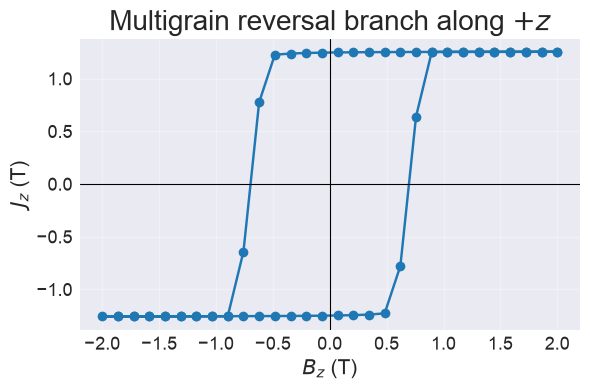

In [62]:
# NBVAL_SKIP
required_columns = {"B_ext_T", "J_par_T"}
missing_columns = required_columns.difference(hysteresis_data.dtype.names)
if missing_columns:
    raise RuntimeError(f"Missing TOMMOS hysteresis columns: {sorted(missing_columns)}")

# TOMMOS reports scalar projections along h = (H_stop - H_start) / |H_stop - H_start|.
tommos_direction = np.asarray(H_stop) - np.asarray(H_start)
tommos_direction /= np.linalg.norm(tommos_direction)

# Use the initial +z field direction as the laboratory reference axis.
reference_direction = np.asarray(H_start, dtype=float)
reference_direction /= np.linalg.norm(reference_direction)
direction_projection = float(np.dot(tommos_direction, reference_direction))
if not np.isclose(abs(direction_projection), 1.0):
    raise RuntimeError("The TOMMOS and plotting directions are not collinear.")

B_reference = hysteresis_data["B_ext_T"] * direction_projection
J_reference = hysteresis_data["J_par_T"] * direction_projection

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(
    B_reference,
    J_reference,
    marker="o",
    color="tab:blue",
)
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(
    xlabel=r"$B_z$ (T)",
    ylabel=r"$J_z$ (T)",
    title="Multigrain reversal branch along $+z$",
)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()